# End-to-end linear penalty model

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "../")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

### Step 1 - construct dose rate matrix

In [2]:
## Choose dose points ##
#dose_points = np.array([(1, 0, -1), (1, 0, -0.5), (1, 0, 1.5)]) # cm - note that these are the same across all output files

# Setting dose points to be on circle in X, Z plane centered at (X, Z) = (2, 0) of radius = 0.5 cm
# x = r*cos(theta), y = r*sin(theta)
# r = 0.5 cm, theta = pi/2 --> (x, z) = (0, 0.5) --> (2, 0.5)
# (x_0 + r*cos(theta), y_0 + r*sin(theta))

def polar_to_cart(coords: np.ndarray, origin: tuple) -> np.ndarray:
    # For now, assuming Y axis is constant at Y = 0
    # In other words, all our dosing points are assumed to be in the plane Y = 0 (for initial sims/debugging)
    # Need to make this more general so you can set an arbitrary axis constant
    # Strictly speaking, we should pass this function source_plane using the Y-coordinate of the source
    # Actually, this may not be necessary since this is just a helper function to choose dosing points in a 2D plane
    # In reality, we're choosing dosing points in 3 dimensions - this just makes choosing test dose points easier!

    # Consider generalizing this to 3D using spherical coordinates?
    cart = []
    for p in coords:
        # p is a tuple = (X, Y)
        c = (origin[0] + p[0]*np.cos(p[1]), 0, origin[1] + p[0]*np.sin(p[1]))
        cart.append(c)
    return np.array(cart)

coords = np.array([(0.5, 0), (0.5, pi/4), (0.5, pi/2), (0.5, 3*pi/4), (0.5, pi), (0.5, 5*pi/4), (0.5, 6*pi/4), (0.5, 7*pi/4)])
origin = (2, 1)
dose_points = polar_to_cart(coords, origin)
print(dose_points)

## Choose source dose rate ##
source_dose_rate = 5 # Gy/s - same across all output files

## Set dwell positions ##
dwell_pos_transZ = np.array([-0.5, -0.4, -0.3, -0.2, -0.1, 0]) # cm - assuming source is centered in applicator (x, y) = (0, 0)

# Other parameters
output_files = np.array(["rate_extract_test_5.csv", "rate_extract_test_4.csv", "rate_extract_test_3.csv", "rate_extract_test_2.csv", 
                        "rate_extract_test_1.csv", "rate_extract_test_0.csv"])
file_location = "rate_extraction_test/"

num_dwell_pos = np.shape(output_files)[0]
num_dose_points = np.shape(dose_points)[0]

# Number of bins and dosing grid half-length - both set in TOPAS parameter files
bins_mosh = 100
dose_grid_half_mosh = 5 # cm

# Computes the lattice length for the simulation space in cm
lattice_mosh = dose_grid_half_mosh*2/bins_mosh

# Error handling
if np.shape(dwell_pos_transZ)[0] != np.shape(output_files)[0]:
    raise ValueError("Number of dwell position Z coordinates must match number of output files")

[[2.5        0.         1.        ]
 [2.35355339 0.         1.35355339]
 [2.         0.         1.5       ]
 [1.64644661 0.         1.35355339]
 [1.5        0.         1.        ]
 [1.64644661 0.         0.64644661]
 [2.         0.         0.5       ]
 [2.35355339 0.         0.64644661]]


#### Visualize dose points

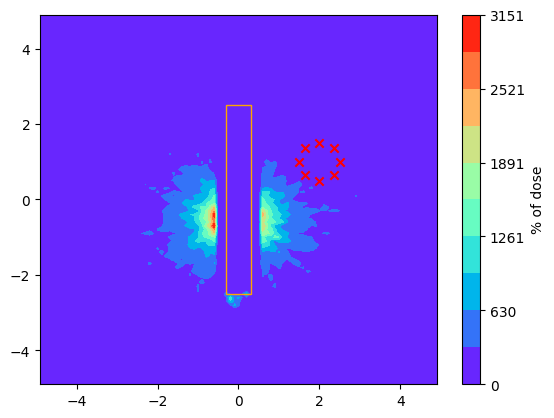

In [3]:
#### Define parameters ####
source_transY = 0

# 0 = x, 1 = y, 2 = z
const_axis = 1 # note the change from prior plots here - this view should be more convenient for dwell position runs

# Set the range of our contour plots
# Maximum range set by TOPAS parameter files
rngX = (-5, 5)
rngY = (-5, 5)

origin = (0, 0)
zero_region = "rectangle"
source_rect = (1.2, 5) # cm

dose = 100 # % of dose
# Compute the plane of the source
source_plane = cm_to_voxel(np.array(source_transY), bins_mosh, lattice_mosh) # note change to using transY as constant, not transZ

#### Construct plot ####
dose_point_1 = ((dose_points[0])[0], (dose_points[0])[2])
dose_point_0, dose_point_voxel = extract_norm_energy(file_location + output_files[0], source_plane, const_axis, dose_point_1, 
                                                     bins_mosh, lattice_mosh)

X, Y, energy0, std_dev = contour_energy(file_location + output_files[0], (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY,
                                        scale=True, norm_energy=dose_point_0, dose=dose, 
                                        zero_source=True, zero_region=zero_region, origin=origin, source_rad=0, source_rect=source_rect,
                                        std_dev=True)

# Plot
fig0, ax0 = plt.subplots()
Xv, Yv = np.meshgrid(X, Y, indexing='ij') # this indexing is important - otherwise contour plot will be rotated

contour0 = ax0.contourf(Xv, Yv, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar0 = fig0.colorbar(contour0, label="% of dose")

# Draw applicator
applicator = plt.Rectangle((-0.3, -2.5), 0.6, 5.0, edgecolor="orange", fill=False)
ax0.add_patch(applicator)

# Add dosing points
for p in dose_points:
    ax0.scatter(p[0], p[2], c="red", marker="x")

In [4]:
"""
D = np.zeros((num_dose_points, num_dwell_pos))

for j in range(num_dwell_pos):
    # Step 1 - extract normalized dose rate @ source
    source_plane = cm_to_voxel(np.array(dwell_pos_transZ[j]), bins_mosh, lattice_mosh)
    source_energy, __ = extract_norm_energy(file_location + output_files[j], source_plane, 2, (0, 0), bins_mosh, lattice_mosh)

    # Step 2 - iterate over dose points, extract energy, and scale to source_energy
    for i in range(num_dose_points):
        dose_point_transZ = dose_points[i][2]
        
        dose_plane = cm_to_voxel(np.array(dose_point_transZ), bins_mosh, lattice_mosh)
        dose_energy, __ = extract_norm_energy(file_location + output_files[j], dose_plane, 2, (dose_points[i][0], dose_points[i][1]), bins_mosh, lattice_mosh)

        normed_dose_energy = (dose_energy/source_energy)*source_dose_rate
        D[i][j] = normed_dose_energy

print(D)
"""
# Test dose_rate_matrix function from plotting_functions
D_test = dose_rate_matrix(output_files, dose_points, dwell_pos_transZ, source_dose_rate, bins_mosh, dose_grid_half_mosh, 
                         file_ext=file_location, save=True, save_name="test_D_matrix.npy")

### Step 2 - run linear penalty model

In [5]:
## Define basic optimization parameters ##
# These parameters from Alterovitz et al. (2006) - for dose to prostate surface 
D_min = 9.5 # Gy
D_max = 15 # Gy
M_l = 100 # penalty/Gy
M_u = 100 # penalty/Gy

# Unpack the dose rate matrix from the locally stored file
D = np.load("test_D_matrix.npy")
print(D)

### NOTE: this dose rate matrix may be incorrect as of 12/04 @ 11:00 ###
# Realized that the order in which dose_rate_matrix extract data from each sim is important for the linear algebra below to work 
# So, the input files need to be sorted from (lowest dwell position) --> (highest dwell position)
# The test array above is organized lowest ---> highest, so the matrix below IS correct
# But need to make sure we have efficient indexing for our actual runs

[[0.00026379 0.00032103 0.00026736 0.00020913 0.00026754 0.00018899]
 [0.00026096 0.0001809  0.00013481 0.0002735  0.00045591 0.00016785]
 [0.00030017 0.00036306 0.00048097 0.00047643 0.00042901 0.00028784]
 [0.00023365 0.00028438 0.00056422 0.0003987  0.00033977 0.00047022]
 [0.00043772 0.00039331 0.00045838 0.00087382 0.00034658 0.00093838]
 [0.0005387  0.00068349 0.0011219  0.00059586 0.00049027 0.0007395 ]
 [0.0004004  0.00019482 0.00058907 0.00053147 0.00055886 0.00082581]
 [0.00061218 0.00019842 0.00035327 0.00051021 0.00032578 0.00060657]]


In [6]:
# Construct the bounds A_ub and b_ub
# Step 1 - construct A matrix for dwell time vector (size 2r x c)
A_t = np.vstack((-M_l*D[0,:], M_u*D[0,:]))
for j in range(1, num_dose_points):
    A_t = np.vstack((A_t, -M_l*D[j,:], M_u*D[j,:]))
print(A_t)

# Step 2 - construct A matrix for dose point vector (size 2r x r)
A_w = -1*np.identity(num_dose_points)
for j in range(0, num_dose_points):
    A_w = np.insert(A_w, 2*j, A_w[2*j,:], axis=0)
print(A_w)

# Step 3 - combine to create A_ub
A_ub = np.hstack((A_t, A_w))
print(A_ub)

# Step 4 - construct b_ub
b_ub = np.reshape(np.full((num_dose_points,2), [-M_l*D_min, M_u*D_max]), 2*num_dose_points)
print(b_ub)

[[-0.02637902 -0.03210329 -0.02673586 -0.02091267 -0.02675376 -0.01889907]
 [ 0.02637902  0.03210329  0.02673586  0.02091267  0.02675376  0.01889907]
 [-0.02609626 -0.01809016 -0.01348142 -0.02735037 -0.04559143 -0.01678535]
 [ 0.02609626  0.01809016  0.01348142  0.02735037  0.04559143  0.01678535]
 [-0.03001654 -0.03630554 -0.04809665 -0.04764264 -0.04290092 -0.02878412]
 [ 0.03001654  0.03630554  0.04809665  0.04764264  0.04290092  0.02878412]
 [-0.02336483 -0.02843787 -0.05642233 -0.03986961 -0.0339774  -0.04702244]
 [ 0.02336483  0.02843787  0.05642233  0.03986961  0.0339774   0.04702244]
 [-0.04377244 -0.03933058 -0.04583771 -0.08738218 -0.03465805 -0.09383762]
 [ 0.04377244  0.03933058  0.04583771  0.08738218  0.03465805  0.09383762]
 [-0.05387047 -0.06834947 -0.11218984 -0.05958595 -0.04902677 -0.07395025]
 [ 0.05387047  0.06834947  0.11218984  0.05958595  0.04902677  0.07395025]
 [-0.04004044 -0.01948185 -0.05890662 -0.05314677 -0.05588569 -0.08258121]
 [ 0.04004044  0.01948185

In [7]:
# Construct the parameter vector c
# Number of 0 entries = number of dwell positions
# Number of 1 entries = number of dose points
c = np.concatenate((np.zeros(num_dwell_pos), np.ones(num_dose_points)))
print(c)

[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
# Set up the optimization
from scipy.optimize import linprog
res = linprog(c, A_ub=A_ub, b_ub=b_ub)
print(res.fun)
print(res.x)
res.message

151.56273836033796
[ 1297.47993818  3117.06511825     0.             0.
 24824.28357787     0.           151.56273836     0.
     0.             0.             0.             0.
     0.             0.        ]


'Optimization terminated successfully. (HiGHS Status 7: Optimal)'

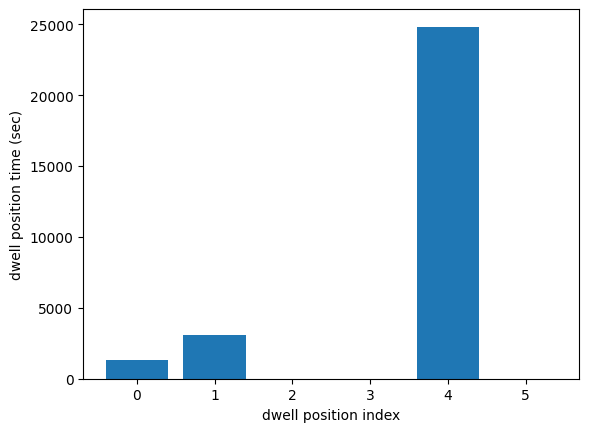

In [9]:
# Plot dwell time vs dwell position
dwell_pos_index = np.arange(num_dwell_pos)
dwell_pos_time = res.x[0:num_dwell_pos]

fig1, ax1 = plt.subplots()
ax1.bar(dwell_pos_index, dwell_pos_time)
ax1.set_xlabel('dwell position index')
ax1.set_ylabel('dwell position time (sec)')
plt.show()

In [29]:
# Debugging - testing sorting of Python strings via Numpy
test_array = np.array(["test-1t-1n_4.csv", "test-1t-1n_6.csv", "test-1t-1n_1.csv", "test-1t-1n_3.csv", "test-1t-1n_2.csv", "test-1t-1n_5.csv", 
                       "test-1t-1n_0.csv", "test-1t-1n_10.csv", "test-1t-1n_18.csv", "test-1t-1n_-22.csv", "test-1t-1n_-35.csv", "test-1t-1n_-1.csv"])
test_2 = np.array(["1_test", "10_test", "6_test", "0_test", "101_test"])

test_sort = np.sort(test_array)
#print(test_sort)

test_sort_2 = np.sort(test_2)
#print(test_sort_2)

# Create dictionary ---> sort via value of string in dictionary
#c = int(test_array[0].split("_")[1])
#test_dict = {test_array[0] : c}
#print(test_dict)

# Instead of dictionary, sort using argsort and then index appropriately
indices = []
for s in test_array:
    s = os.path.splitext(s)[0]
    c = int(s.split("_")[1])
    indices.append(c)
arg_sorted = np.argsort(np.array(indices))
print(test_array[arg_sorted])
# Note that the actual indices don't matter - they just have to be monotonically increasing

# Additional debugging
dwell_pos_Z = np.array([x for x in range(-25, 26)])/10
print(dwell_pos_Z)

['test-1t-1n_-35.csv' 'test-1t-1n_-22.csv' 'test-1t-1n_-1.csv'
 'test-1t-1n_0.csv' 'test-1t-1n_1.csv' 'test-1t-1n_2.csv'
 'test-1t-1n_3.csv' 'test-1t-1n_4.csv' 'test-1t-1n_5.csv'
 'test-1t-1n_6.csv' 'test-1t-1n_10.csv' 'test-1t-1n_18.csv']
[-2.5 -2.4 -2.3 -2.2 -2.1 -2.  -1.9 -1.8 -1.7 -1.6 -1.5 -1.4 -1.3 -1.2
 -1.1 -1.  -0.9 -0.8 -0.7 -0.6 -0.5 -0.4 -0.3 -0.2 -0.1  0.   0.1  0.2
  0.3  0.4  0.5  0.6  0.7  0.8  0.9  1.   1.1  1.2  1.3  1.4  1.5  1.6
  1.7  1.8  1.9  2.   2.1  2.2  2.3  2.4  2.5]
